# Aggregates: Monaco, Ghio & Perrotta (2024)

This notebook reproduces the multi-aggregate extension of the DY model by Monaco, Ghio & Perrotta (2024). Agents belong to aggregates (communities), and at every step two exchanges take place: agents exchange money, and aggregates exchange members. Wealth is then tracked per aggregate, as the sum of the wealth of its members.

#### Step 1: Monetary exchange
- Choose two distinct agents $i$ (winner) and $j$ (loser) uniformly at random
- Draw $\Delta m \sim U(0, m)$
- If $m_j \ge \Delta m$: $\ m_i \rightarrow m_i + \Delta m$ and $m_j \rightarrow m_j - \Delta m$

#### Step 2: Aggregate exchange
- Choose two distinct aggregates $p$ (receiver) and $q$ (donor) uniformly at random
- Draw the number of migrating agents $\Delta n$ uniformly from $\{0, 1, \dots, d\}$
- If $d_q \ge \Delta n$, move $\Delta n$ randomly chosen members of $q$ to $p$: $\ d_p \rightarrow d_p + \Delta n$ and $d_q \rightarrow d_q - \Delta n$

Aggregate sizes follow the same no-debt exchange rule as money in the DY model, with members playing the role of money.

In [8]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed()  # for reproducibility

### Simulation

$N_a = 1000$ aggregates start with $d = 10$ members each, and every agent starts with wealth $m = 100$. Aggregate wealth and size are recorded every 1% of the run. Entropy uses bins of width $m$ for aggregate wealth and unit-width bins for aggregate size.

The aggregate totals are computed with `np.bincount`, which is $O(N)$ per measurement, so the run takes about a minute.

In [9]:
### PARAMS -----------------------------------------------------------------------------------------------------------------------

Na = 1000 # number of aggregates
d = 10 # initial size of each aggregate
m = 100 # initial wealth per agent
sims = 10**5

D = Na * d # total agents
M = m * D # total wealth

### SET UP -----------------------------------------------------------------------------------------------------------------------

wealth = np.ones(D) * m
member = np.repeat(np.arange(Na), d) # member[k] = aggregate of agent k
record = sims // 100 # record every 1% of simulations

def entropy(values, width):
    bin_edges = np.arange(0, values.max() + width, width)
    vec, _ = np.histogram(values, bins = bin_edges)
    vec = vec[vec != 0] # avoid log(0)
    Pb = vec / len(values)
    return -np.sum(Pb * np.log(Pb))

wealth_entropy = []
agg_entropy = []

### PIPELINE -----------------------------------------------------------------------------------------------------------------------

for k in range(sims):

    ### MONETARY EXCHANGE (j loses)
    i, j = np.random.randint(D, size = 2)
    if i != j:
        dm = np.random.uniform(0, m)
        if wealth[j] >= dm:
            wealth[i] += dm
            wealth[j] -= dm

    ### AGGREGATE EXCHANGE (q loses members to p)
    p, q = np.random.randint(Na, size = 2)
    if p != q:
        dn = np.random.randint(0, d + 1)
        if dn > 0:
            agg_q = np.flatnonzero(member == q)
            if agg_q.size >= dn:
                movers = np.random.choice(agg_q, size = dn, replace = False)
                member[movers] = p

    ### RECORD
    if k % record == 0 or k == sims - 1:
        agg_wealth = np.bincount(member, weights = wealth, minlength = Na)
        agg_size = np.bincount(member, minlength = Na)
        wealth_entropy.append(entropy(agg_wealth, m))
        agg_entropy.append(entropy(agg_size, 1))

### Results

Aggregate wealth and size after the run, with the entropy of each over time. Empty aggregates (size 0) are kept, as they can be repopulated. The DY benchmark for sizes is an exponential with mean $d$, overlaid for reference.

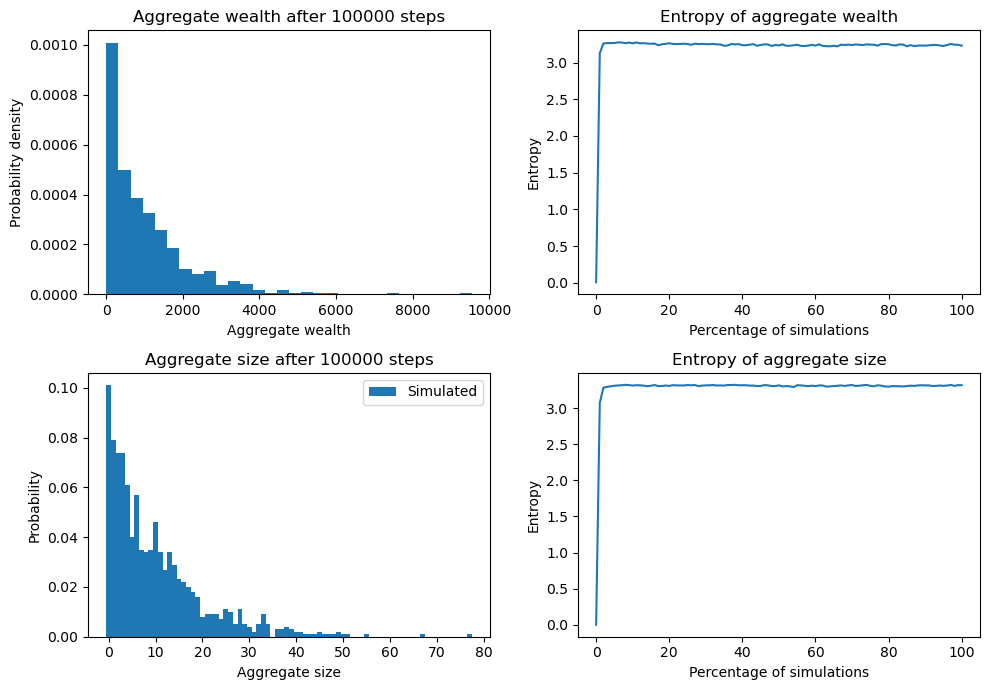

Empty aggregates: 10.1%, largest aggregate: 77 members


In [11]:
fig, axs = plt.subplots(2, 2, figsize=(10, 7))
steps = np.linspace(0, 100, len(wealth_entropy))

axs[0, 0].hist(agg_wealth, bins = 30, density = True)
axs[0, 0].set_title(f"Aggregate wealth after {sims} steps")
axs[0, 0].set_xlabel("Aggregate wealth")
axs[0, 0].set_ylabel("Probability density")

axs[0, 1].plot(steps, wealth_entropy)
axs[0, 1].set_title("Entropy of aggregate wealth")
axs[0, 1].set_xlabel("Percentage of simulations")
axs[0, 1].set_ylabel("Entropy")

size_bins = np.arange(0, agg_size.max() + 2) - 0.5
xs = np.arange(0, agg_size.max() + 1)
axs[1, 0].hist(agg_size, bins = size_bins, density = True, label = "Simulated")
axs[1, 0].set_title(f"Aggregate size after {sims} steps")
axs[1, 0].set_xlabel("Aggregate size")
axs[1, 0].set_ylabel("Probability")
axs[1, 0].legend()

axs[1, 1].plot(steps, agg_entropy)
axs[1, 1].set_title("Entropy of aggregate size")
axs[1, 1].set_xlabel("Percentage of simulations")
axs[1, 1].set_ylabel("Entropy")

plt.tight_layout()
plt.show()

print(f"Empty aggregates: {(agg_size == 0).mean():.1%}, largest aggregate: {agg_size.max()} members")